# Descripteurs spatiaux — Gabor et scattering (scénario opérationnel)

**Question** : des descripteurs de texture plus fins que min / max / écart-type améliorent-ils l'estimation
de l'altitude du sommet des nuages, et rattrapent-ils les 46 m perdus sans correction de parallaxe ?

**Protocole** (identique à l'EDA V2, section 7)
- Données V2, fenêtres 11×11 **brutes** ; aucune variable dérivée de la cible (vérifié par `check_features`).
- Gradient boosting LightGBM, perte MAE, 600 arbres, mêmes réglages qu'à l'EDA.
- Validation croisée **un jour = un pli** (13 plis), comparaison **appariée jour par jour** avec la famille E.

**Descripteurs** (calculés après retrait de la pente, pour chacun des 6 canaux)
- **Gabor** : filtres de Morlet à 3 longueurs d'onde (3, 4, 6 pixels) × 8 orientations. Pour chaque longueur
  d'onde : énergie moyenne sur les orientations (`_e`) et anisotropie (`_aniso`).
- **Scattering simplifié** (ordre 2) : on refiltre le module de la réponse de Gabor à une échelle plus grande.
  Il décrit comment les petites structures s'organisent à plus grande échelle (par exemple des cellules
  alignées en bandes). Résumé par orientation identique (`_par`) et moyenne sur toutes les orientations (`_all`).
- Seules des grandeurs **invariantes à la rotation** sont gardées : le sens du nord n'est pas confirmé et
  l'orientation dominante vue dans l'EDA est un artefact de grille.

| Famille | Contenu | Variables |
|---|---|---|
| E | Base de comparaison de l'EDA (stats 5×5 et 11×11 brutes, physique, texture simple) | 79 |
| F | E + Gabor | 115 |
| G | E + scattering | 115 |
| H | E + Gabor + scattering | 151 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ctth_data as cd

pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})

DATA_PATH = './Data/data_cloud_top_V2.pkl'
CACHE_PATH = './Data/spatial_features_v2.parquet'    # créé au premier lancement (~15-20 min), rechargé ensuite

df, win = cd.load_v2(DATA_PATH)
df = cd.build_features(df, win)
spat = cd.spatial_features(win, cache_path=CACHE_PATH)
df = pd.concat([df, spat.set_index(df.index)], axis=1)
y = df[cd.TARGET].to_numpy()
print(df.shape, '| descripteurs spatiaux :', spat.shape[1])

(87746, 184) | descripteurs spatiaux : 72


## 1. À quoi ressemblent les filtres

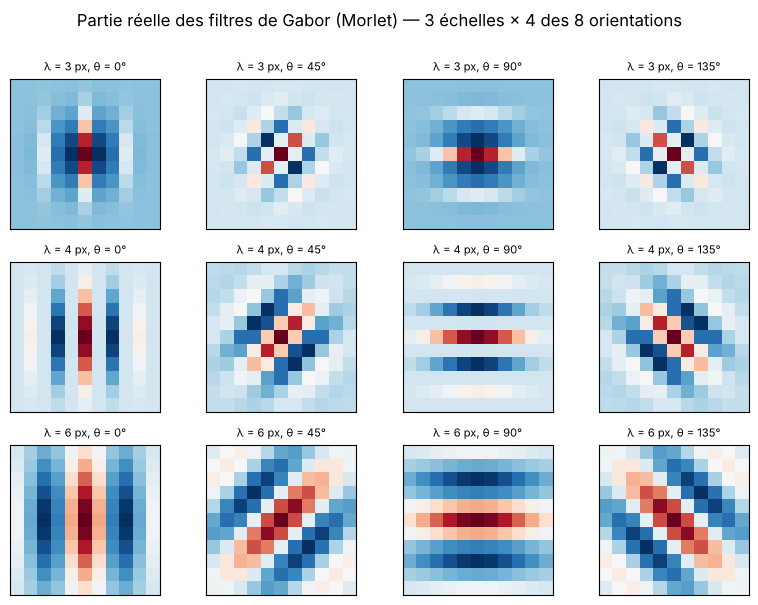

In [2]:
K = cd.gabor_bank()
fig, axes = plt.subplots(len(cd.GABOR_LAMBDAS), 4, figsize=(8, 6))
for i, lam in enumerate(cd.GABOR_LAMBDAS):
    for j, t in enumerate([0, 2, 4, 6]):
        axes[i, j].imshow(K[i, t].real, cmap='RdBu_r'); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        axes[i, j].set_title(f'λ = {lam} px, θ = {t * 180 // cd.GABOR_N_THETA}°', fontsize=8)
fig.suptitle('Partie réelle des filtres de Gabor (Morlet) — 3 échelles × 4 des 8 orientations', y=1.0)
plt.tight_layout(); plt.show()

## 2. Ce que mesurent les descripteurs

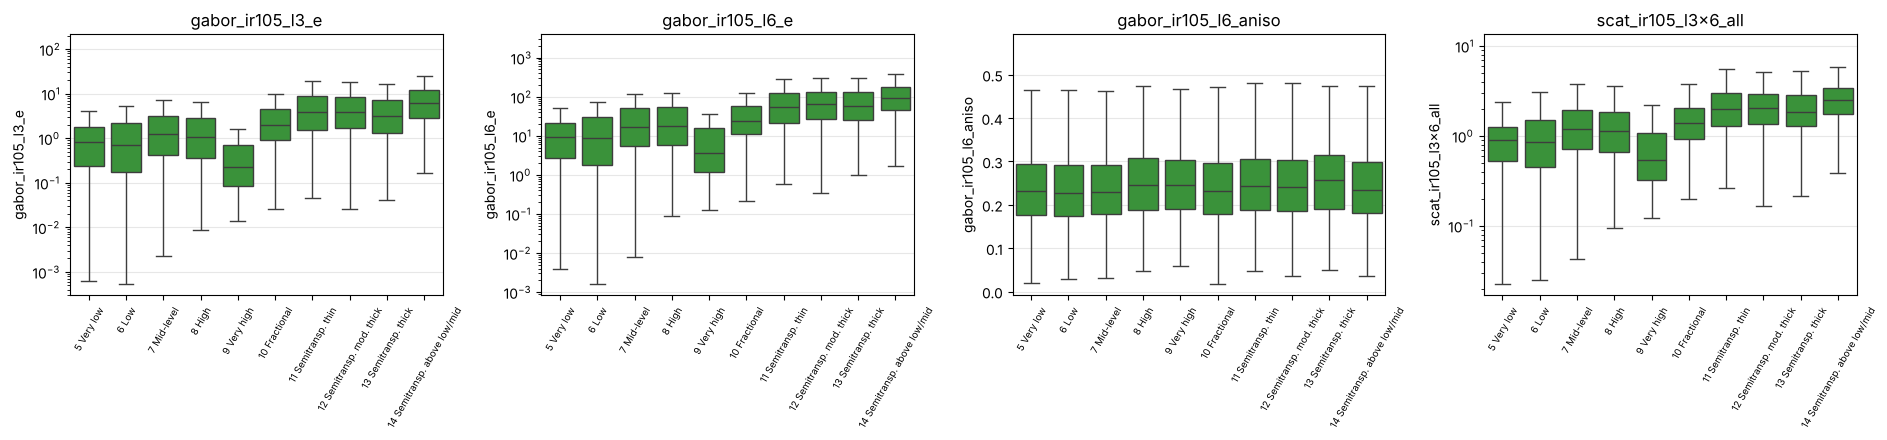

In [3]:
lab = df[cd.CT].map(lambda c: f'{c} {cd.CT_NAMES[c]}')
order = [f'{c} {cd.CT_NAMES[c]}' for c in sorted(df[cd.CT].unique())]
show = ['gabor_ir105_l3_e', 'gabor_ir105_l6_e', 'gabor_ir105_l6_aniso', 'scat_ir105_l3x6_all']
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
for ax, v in zip(axes, show):
    sns.boxplot(x=lab, y=df[v], order=order, ax=ax, color='C2', fliersize=0)
    if not v.endswith('aniso'): ax.set_yscale('log')
    ax.set_title(v); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=60, labelsize=7)
plt.tight_layout(); plt.show()

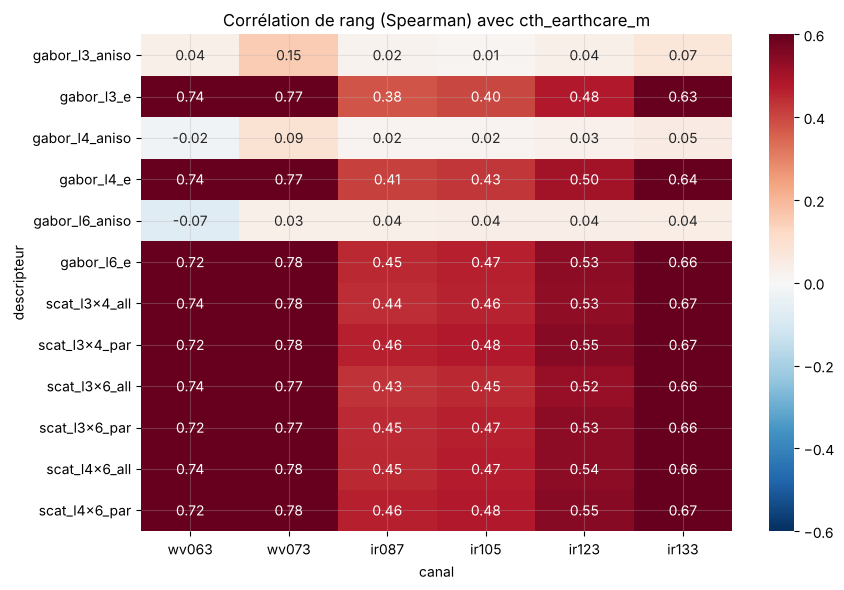

In [4]:
# Lien avec la cible (Spearman), par canal
rho = df[cd.GABOR_FEATURES + cd.SCAT_FEATURES].corrwith(df[cd.TARGET], method='spearman')
tab = rho.rename(lambda s: s.split('_', 2)[2] if False else s).to_frame('rho')
tab['canal'] = [s.split('_')[1] for s in tab.index]
tab['descripteur'] = ['_'.join([s.split('_')[0]] + s.split('_')[2:]) for s in tab.index]
pivot = tab.pivot(index='descripteur', columns='canal', values='rho')[cd.CH]
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-.6, vmax=.6)
plt.title('Corrélation de rang (Spearman) avec cth_earthcare_m'); plt.tight_layout(); plt.show()

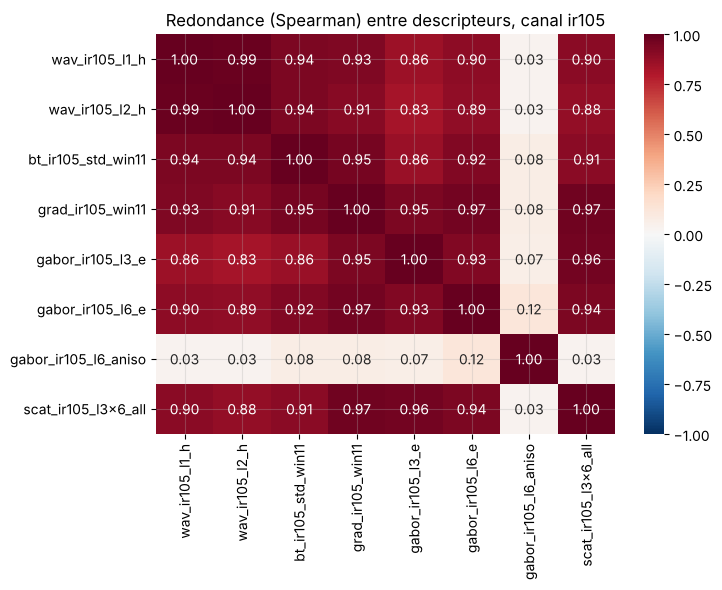

In [5]:
# Redondance avec les variables déjà présentes dans E (énergies d'ondelettes et écart-type, ir105)
cmp = ['wav_ir105_l1_h', 'wav_ir105_l2_h', 'bt_ir105_std_win11', 'grad_ir105_win11',
       'gabor_ir105_l3_e', 'gabor_ir105_l6_e', 'gabor_ir105_l6_aniso', 'scat_ir105_l3x6_all']
plt.figure(figsize=(7.5, 6))
sns.heatmap(df[cmp].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Redondance (Spearman) entre descripteurs, canal ir105'); plt.tight_layout(); plt.show()

## 3. Apport en validation croisée par jour

> Cellule longue (≈ 12 min sur 2 cœurs).

In [6]:
import lightgbm as lgb
prm = dict(objective='l1', n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1)
make = lambda: lgb.LGBMRegressor(**prm)

runs = {}
for fam in ['E', 'F', 'G', 'H']:
    runs[fam] = cd.cross_validate_by_day(df, cd.FAMILIES_V2[fam], make)
    print(fam, len(cd.FAMILIES_V2[fam]), 'variables : MAE', round(runs[fam]['summary']['MAE']), 'm')

summary = pd.DataFrame({f: r['summary'] for f, r in runs.items()}).T
summary['MAE > 8 km'] = [np.abs(r['pred'] - y)[y > 8000].mean() for r in runs.values()]
summary['MAE semi-transp. (11–14)'] = [np.abs(r['pred'] - y)[df[cd.CT].between(11, 14).to_numpy()].mean() for r in runs.values()]
summary.round({'MAE': 0, 'Biais': 0, 'RMSE': 0, 'R2': 3, 'MAE écart-type entre jours': 0, 'MAE > 8 km': 0, 'MAE semi-transp. (11–14)': 0})

E 79 variables : MAE 736 m


F 115 variables : MAE 727 m


G 115 variables : MAE 730 m


H 151 variables : MAE 729 m


,N,MAE,Biais,RMSE,R2,MAE écart-type entre jours,MAE > 8 km,MAE semi-transp. (11–14)
E,87746.0,736.0,-61.0,1399.0,0.899,89.0,1190.0,897.0
F,87746.0,727.0,-50.0,1376.0,0.902,96.0,1155.0,882.0
G,87746.0,730.0,-52.0,1372.0,0.903,91.0,1158.0,891.0
H,87746.0,729.0,-55.0,1377.0,0.902,94.0,1159.0,884.0


In [7]:
# Comparaisons appariées jour par jour (gain positif = la deuxième famille fait mieux)
rows = {f'E → {f}': cd.paired_comparison(runs['E']['by_day'], runs[f]['by_day']) for f in ['F', 'G', 'H']}
rows['F → H (scattering en plus de Gabor)'] = cd.paired_comparison(runs['F']['by_day'], runs['H']['by_day'])
paired = pd.DataFrame(rows).T
paired['gain moyen (m)'] = paired['gain moyen (m)'].astype(float).round(1)
paired['écart-type (m)'] = paired['écart-type (m)'].astype(float).round(1)
paired['p_sign'] = paired['p_sign'].astype(float).round(4)
paired

,gain moyen (m),écart-type (m),jours gagnants,p_sign
E → F,9.9,18.4,9 / 13,0.1334
E → G,6.8,14.4,9 / 13,0.1334
E → H,7.4,16.8,10 / 13,0.0461
F → H (scattering en plus de Gabor),-2.5,9.0,3 / 13,0.9888


/home/claude/analysis/run3/ctth_data.py:387: RuntimeWarning: Mean of empty slice
  return pd.Series({'N': int(m.sum()), 'MAE': np.abs(e).mean(), 'Biais': e.mean(),
/usr/local/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/claude/analysis/run3/ctth_data.py:388: RuntimeWarning: Mean of empty slice
  'RMSE': np.sqrt((e ** 2).mean()),
/home/claude/analysis/run3/ctth_data.py:389: RuntimeWarning: Mean of empty slice
  'R2': 1 - (e ** 2).sum() / ((yt - yt.mean()) ** 2).sum()})
/home/claude/analysis/run3/ctth_data.py:389: RuntimeWarning: invalid value encountered in scalar divide
  'R2': 1 - (e ** 2).sum() / ((yt - yt.mean()) ** 2).sum()})


,E,F,G,H,SAFNWC,gain H vs E,N
5 Very low,499.0,498.0,503.0,501.0,887.0,-1.0,30694
6 Low,859.0,854.0,858.0,856.0,1516.0,3.0,16278
7 Mid-level,689.0,678.0,669.0,682.0,1359.0,7.0,8113
8 High,521.0,514.0,515.0,516.0,1222.0,5.0,6072
9 Very high,839.0,889.0,881.0,900.0,707.0,-61.0,817
10 Fractional,1219.0,1185.0,1177.0,1186.0,NaN,33.0,8313
11 Semitransp. thin,1237.0,1177.0,1181.0,1181.0,1951.0,55.0,4197
12 Semitransp. mod. thick,802.0,800.0,815.0,804.0,1392.0,-2.0,8249
13 Semitransp. thick,556.0,561.0,561.0,561.0,959.0,-5.0,1755
14 Semitransp. above low/mid,881.0,882.0,888.0,880.0,1431.0,2.0,3258


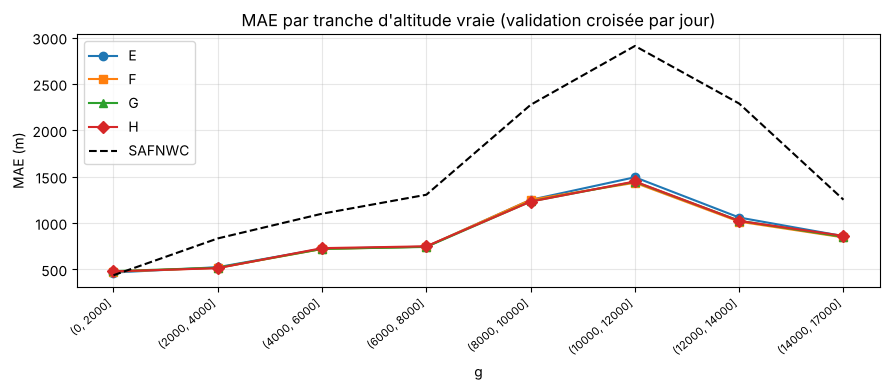

In [8]:
# Détail par type de nuage et par tranche d'altitude
by_ct = pd.DataFrame({f: cd.metrics_by(df, r['pred'])['MAE'] for f, r in runs.items()})
by_ct['SAFNWC'] = cd.metrics_by(df, df[cd.SAF].to_numpy())['MAE']
by_ct['gain H vs E'] = by_ct['E'] - by_ct['H']
by_ct.index = [f'{i} {cd.CT_NAMES[i]}' for i in by_ct.index]
by_ct['N'] = df[cd.CT].value_counts().sort_index().to_numpy()
display(by_ct.round(0))

by_alt = pd.DataFrame({f: cd.metrics_by(df, r['pred'], by='alt_bin')['MAE'] for f, r in runs.items()})
by_alt['SAFNWC'] = cd.metrics_by(df, df[cd.SAF].to_numpy(), by='alt_bin')['MAE']
ax = by_alt.plot(style=['o-', 's-', '^-', 'D-', 'k--'], figsize=(9, 4))
ax.set_xticks(range(len(by_alt)), [str(b) for b in by_alt.index], rotation=40, ha='right', fontsize=8)
ax.set_ylabel('MAE (m)'); ax.set_title("MAE par tranche d'altitude vraie (validation croisée par jour)")
plt.tight_layout(); plt.show()

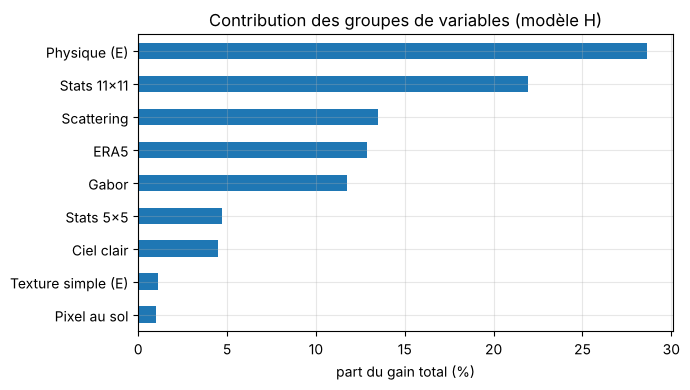

Variables spatiales les plus utilisées :


,gain
scat_wv073_l3x4_all,143913.0
gabor_wv063_l3_e,133734.0
scat_wv073_l3x4_par,61917.0
scat_wv063_l3x4_all,58069.0
gabor_wv073_l6_e,55430.0
scat_wv063_l4x6_all,15050.0
scat_wv073_l4x6_all,11747.0
gabor_ir087_l3_e,10978.0
gabor_wv073_l3_e,9356.0
gabor_wv073_l4_e,8618.0


In [9]:
# Poids de chaque groupe de variables dans le modèle H (gain cumulé des arbres, modèle entraîné sur tout le jeu)
mH = make().fit(df[cd.FAMILIES_V2['H']].to_numpy(np.float32), y)
imp = pd.Series(mH.booster_.feature_importance('gain'), index=cd.FAMILIES_V2['H'])
def group(v):
    if v.startswith('gabor'): return 'Gabor'
    if v.startswith('scat'): return 'Scattering'
    if v.startswith(('wav', 'grad', 'coherence')): return 'Texture simple (E)'
    if v.startswith('dbt') or v == 'cth_era5inv_m': return 'Physique (E)'
    if v.endswith(('_win11',)): return 'Stats 11×11'
    if v.endswith('_p5raw'): return 'Stats 5×5'
    if v.startswith('t_era5'): return 'ERA5'
    if v.endswith('_clearsky'): return 'Ciel clair'
    return 'Pixel au sol'
share = (imp.groupby(imp.index.map(group)).sum() / imp.sum() * 100).sort_values()
share.plot.barh(figsize=(7, 4), color='C0'); plt.xlabel('part du gain total (%)')
plt.title('Contribution des groupes de variables (modèle H)'); plt.tight_layout(); plt.show()
print('Variables spatiales les plus utilisées :')
display(imp[[v for v in imp.index if v.startswith(('gabor', 'scat'))]].sort_values(ascending=False).head(10).round(0).to_frame('gain'))

## 4. Conclusions

**Résultat principal : Gabor et scattering apportent un gain réel mais petit, et non démontré statistiquement à lui seul.**

| Comparaison (13 plis par jour) | Gain moyen | Jours gagnants | p (test du signe) |
|---|---|---|---|
| E → F (+ Gabor) | −10 m | 9 / 13 | 0,13 |
| E → G (+ scattering) | −7 m | 9 / 13 | 0,13 |
| E → H (+ les deux) | −7 m | 10 / 13 | 0,05 |
| F → H (scattering en plus de Gabor) | +3 m | 3 / 13 | — |

- **F atteint 727 m, soit le niveau de la version avec fuite (B : 728 m).** En moyenne, les descripteurs de texture compensent donc l'absence de correction de parallaxe, mais l'écart avec E (736 m) reste du même ordre que le bruit d'un jour à l'autre.
- **Le scattering n'apporte rien de plus que Gabor** (meilleur seulement 3 jours sur 13). Les deux mesurent presque la même chose : leurs corrélations avec la cible sont quasi identiques, quel que soit le descripteur.
- **L'anisotropie est inutile** (corrélation ≈ 0 pour tous les canaux et toutes les échelles) : la direction des structures ne renseigne pas sur l'altitude, ce qui confirme l'EDA.
- **Les gains se concentrent là où on les attendait** : cirrus fins (type 11, −55 à −60 m) et nuages fractionnés (type 10, −33 à −42 m). Sur les nuages bas, rien ne change. **Les nuages très hauts (type 9) se dégradent** (+40 à +60 m), sur seulement 817 pixels : à surveiller, le SAFNWC reste meilleur sur ce type.
- **Découverte : la texture des canaux vapeur d'eau (6,3 et 7,3 µm) est la plus informative de toutes** (Spearman ≈ 0,75 à 0,78), devant les canaux fenêtre IR (0,4 à 0,5) et devant toute autre variable du projet. Ce sont aussi les descripteurs spatiaux les plus utilisés par le modèle. Interprétation physique probable : ces canaux ne « voient » que la haute troposphère, donc une structure n'y apparaît que si un nuage haut est présent.
- Dans le modèle H, les descripteurs spatiaux représentent environ **25 % du gain total** (Gabor ≈ 12 %, scattering ≈ 13 %), mais ils remplacent en partie l'information des statistiques simples plutôt que de l'ajouter.

**Décisions pour la suite**
1. Garder **F (E + Gabor, sans anisotropie)** comme nouvelle base de comparaison : 727 m. Abandonner le scattering et l'anisotropie, qui ne rapportent rien.
2. Les descripteurs construits à la main plafonnent autour de 730 m avec le gradient boosting. Pour aller plus loin, il faut un modèle qui apprend lui-même les structures spatiales : **petit CNN sur le cube 6 × 11 × 11**, en donnant aux canaux vapeur d'eau une place centrale.
3. Tester le **MLP corrigé** (activation sur toutes les couches, cible en km) sur la famille F, pour vérifier s'il garde l'avantage qu'il avait sur l'ancien jeu (564 m contre 785 m pour LightGBM sur le jour de test V1).
